# 2B2 — Arrays, models, and plotting

We’ll use simulated observations to work with paired arrays, model curves,
residuals, and functions. Each example and exercise keeps its data and
calculations together in one code block.

## Setup

Run these imports once when starting or restarting the kernel. Each block
then runs independently. The blocks reset the random seed to 42 for
repeatable data; noise is drawn from a normal distribution centred on zero.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

## Plotting simulated observations

An **observation** is a paired input and output: matching positions in `x_obs` and `y_obs` belong together. Let’s generate inputs, calculate outputs, and add noise. For crowded data, a **2D histogram** counts observations in rectangles; its colourbar shows the counts. `norm='log'` gives the colour scale logarithmic spacing.

### Code Reference

| Code | What it does |
| :--- | :--- |
| `np.random.seed(42)` | Restart the random sequence for repeatable results. |
| `np.random.normal(2, 4, size=N)` | Generate N normal random values: centre 2, scale 4. Scale is the distribution’s standard deviation. |
| `3 * x_obs**2 + noise` | Calculate an output for each input and add matching noise values. |
| `plt.figure()` | Start a fresh figure. |
| `plt.plot(x_obs, y_obs, '.', alpha=0.5)` | Draw points; alpha controls transparency. |
| `plt.hist2d(x_obs, y_obs, bins=80, cmap='Blues', norm='log')` | Group paired observations into rectangular bins. |
| `plt.colorbar()` | Show the histogram’s count scale. |
| `plt.show()` | Display the completed figure. |

Documentation: [normal](https://numpy.org/doc/stable/reference/random/generated/numpy.random.normal.html), [plot](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.plot.html), [hist2d](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.hist2d.html).

### Exercises

**Example: Generate and plot observations**

- **Generate:** `N = 100` inputs with `np.random.normal(2, 4, size=N)`.
- **Calculate:** `3 * x_obs**2`.
- **Plot:** the points with `'.'` and `alpha=0.5`.

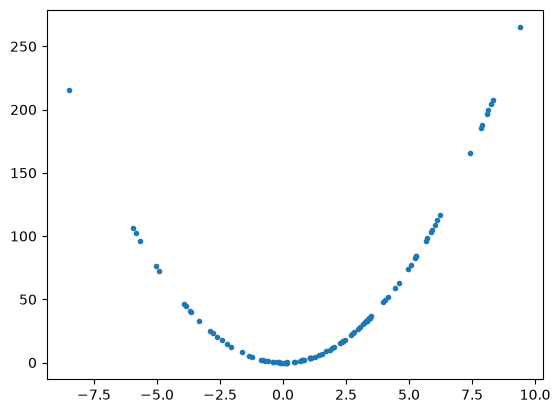

In [2]:
np.random.seed(42)
N = 100
x_obs = np.random.normal(2, 4, size=N)
y_obs = 3 * x_obs**2

plt.figure()
plt.plot(x_obs, y_obs, '.');

**Exercise: Add noise**

- **Generate:** `N = 100` inputs with `np.random.normal(2, 4, size=N)`.
- **Calculate:** `3 * x_obs**2` and add noise from `np.random.normal(0, 30, size=N)`.
- **Plot:** the points with `'.'` and `alpha=0.5`.

**Exercise: Plot a lot of data at once**

Plot 100,000 data points, and reduce it looking like one big blob.

- **Generate:** `N = 100_000` (ten thousand) inputs with `np.random.normal(2, 4, size=N)`.
- **Calculate:** `3 * x_obs**2` and add noise from `np.random.normal(0, 15, size=N)`.
- **Plot:** the points
  - *Okay Method*: Put `alpha=.05` in the plot command to make overlapping points 95% transparant: `plt.plot(x_obs, y_obs, '.', alpha=0.05)`
  - *Better Method*: Use `plt.hist2d()` to make the scatter plots: `plt.hist2d(x_obs, y_obs, bins=300, cmap='Blues', norm='log')`

## Plotting a separate model

A **model** is an equation we use to predict outputs from inputs. Let’s draw one alongside the observations. Keep the noisy data in `x_obs` and `y_obs`; calculate the model on a separate, ordered grid in `x` and `y`.

### Code Reference

| Code | What it does |
| :--- | :--- |
| `np.min(x_obs), np.max(x_obs)` | Find the smallest and largest observed inputs. |
| `x = np.linspace(start, stop, 60)` | Make 60 evenly spaced values, including both endpoints. |
| `y = 3 * x**2` | Calculate model outputs on the display grid. |
| `plt.plot(x_obs, y_obs, '.')` | Draw the observed input–output pairs as points. |
| `plt.plot(x, y, '--k')` | Draw a dashed black line, connecting points in array order. |

Documentation: [linspace](https://numpy.org/doc/stable/reference/generated/numpy.linspace.html), [plot](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.plot.html).

### Exercises

**Example: Draw a proposed model**: Fit a model to the data and plot a regression line showing the model against the data.

- **Generate:** Use the data `x_obs` and `y_obs` generated below.
- **Calculate:** Model `x` with `np.linspace(np.min(x_obs), np.max(x_obs), 60)`, then `y = 3 * x**2`.
- **Plot:** the observations with `'.'` and the model with `'--k'`.

Data:

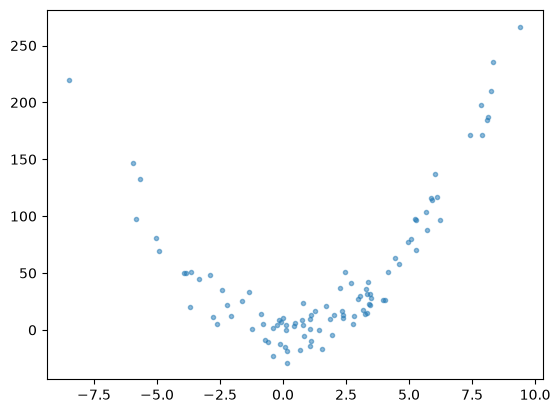

In [32]:
np.random.seed(42)
N = 100
x_obs = np.random.normal(2, 4, size=N)
noise = np.random.normal(0, 15, size=N)
y_obs = 3 * x_obs**2 + noise
plt.plot(x_obs, y_obs, '.', alpha=0.5);

Model:

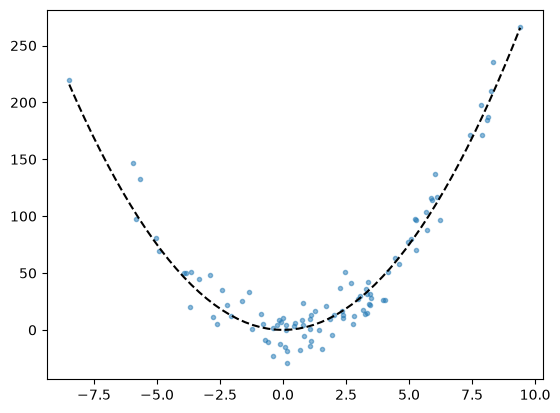

In [33]:
x = np.linspace(np.min(x_obs), np.max(x_obs), 60)
y = 3 * x**2

plt.figure()
plt.plot(x_obs, y_obs, '.', alpha=0.5)
plt.plot(x, y, '--k');

**Exercise: Change the model coefficient**

- **Generate:** Use the data `x_obs` and `y_obs` generated below.  (**This time, the model parameters aren't visible in the code**)
- **Calculate:** `x` with `np.linspace(np.min(x_obs), np.max(x_obs), 60)`, then `y = 2 * x**2`.
- **Plot:** the observations with `'.'` and the model with `'--k'`.

Data:

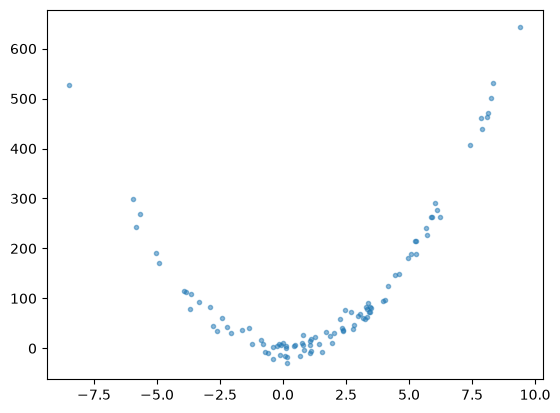

In [47]:
np.random.seed(42)
N = 100
x_obs = np.random.normal(2, 4, size=N)
noise = np.random.normal(0, 15, size=N)
y_obs = np.random.uniform(2, 8)  * x_obs**2 + noise   # the data is generated this time with a secret parameter value!

plt.plot(x_obs, y_obs, '.', alpha=0.5);

Model:  Guess the secret parameter, adjusting the `a` in (`y = a * x ** 2`) until the line fits the data well.

## Compare observations and predictions

Let's calculate a prediction for each observed input and subtract it from the observed output. This difference is called a residual; we can plot it on its own or beside the model curve.

### Code Reference

| Code | What it does |
| :--- | :--- |
| `y_pred = 3 * x_obs**2` | Calculate one prediction for each observed input. |
| `y_err = y_obs - y_pred` | Calculate residuals: observed outputs minus predictions. |
| `plt.axhline(0, color='black', linestyle=':')` | Draw a horizontal line at zero. |
| `plt.subplot(1, 2, 1)` | Choose the left panel: one row, two columns, first position. |
| `plt.subplot(1, 2, 2)` | Choose the right panel. |

Documentation: [subplot](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.subplot.html).

### Exercises

**Example: Calculate and plot residuals**

- **Generate:** Use the data generated below
- **Calculate:** `y_pred = 3 * x_obs**2`, then `y_err = y_obs - y_pred`.
- **Plot:** `y_err` against `x_obs`, with a horizontal line at zero.

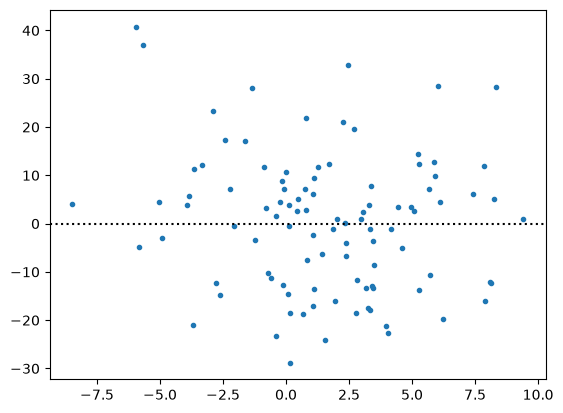

In [ ]:
np.random.seed(42)
x_obs = np.random.normal(2, 4, size=100)
noise = np.random.normal(0, 15, size=100)
y_obs = 3 * x_obs**2 + noise


In [ ]:

y_pred = 3 * x_obs**2
y_err = y_obs - y_pred

plt.figure()
plt.plot(x_obs, y_err, '.')
plt.axhline(0, color='black', linestyle=':');

**Exercise: Minimize average error**: Find the value for `a` that makes the model errors hover around 0 to get a best fit model.

- **Generate:** Use the data generated below
- **Calculate:** `y_pred = a * x_obs**2`, then `y_err = y_obs - y_pred`.  
- **Plot:** `y_err` against `x_obs`, with a horizontal line at zero.

In [57]:
np.random.seed(42)
x_obs = np.random.normal(2, 4, size=100)
noise = np.random.normal(0, 15, size=100)
y_obs = np.random.uniform(-3, 6) * x_obs**2 + noise


**Exercise: Minimize average error**: Use `plt.subplot(1, 2, 1)` and `plt.subplot(1, 2, 2)` to plot the model and the model residuals side-by-side.

- **Generate:** Use the data generated below
- **Calculate:** `y_pred = a * x_obs**2`, then `y_err = y_obs - y_pred`.  
- **Plot:** `y_err` against `x_obs`, with a horizontal line at zero.

In [64]:
np.random.seed(42)
x_obs = np.random.normal(2, 4, size=100)
noise = np.random.normal(0, 15, size=100)
y_obs = np.random.uniform(-3, 6) * x_obs**2 + noise


## Reuse calculations with functions

A **function** gives a calculation a name so we can call it again. **Parameters** are the named inputs in its definition. The indented `return` line gives the result back. For a model, this lets us use one definition both for drawing a curve and for predicting at the observed inputs.

### Code Reference

| Code | What it does |
| :--- | :--- |
| `def square_model(x, a):` | Define a function with inputs x and a. The body is indented below the colon. |
| `return a * x**2` | Return the calculated array from the function. |
| `square_model(x, 3)` | Call the model on the plotting grid with a set to 3. |
| `square_model(x_obs, 3)` | Call it at the observed inputs to obtain matching predictions. |
| `len(x)` | The number of entries in a one-dimensional array; useful for matching the noise-array size. |
| `popt, pcov = curve_fit(square_model, x_obs, y_obs)` | Fit a model to the observations. popt contains the fitted parameters; pcov is unused here. |
| `square_model(x, *popt)` | Use the supplied pattern to call the model with fitted values. |
| `print(popt)` | Display the fitted values in the order of the parameters after x. |

Documentation: [functions](https://docs.python.org/3/tutorial/controlflow.html#defining-functions), [curve_fit](https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.curve_fit.html).

### Demos

No need to write anything; just take a look at how functions are used to re-use models and help numpy fit model parameters automatically!

**Demo: Fit a model function**

- **Generate:** `N = 100`; inputs `np.random.normal(2, 4, size=N)`; outputs `3 * x_obs**2 + 20` plus noise with scale 15.
- **Fit:** Define `square_model(x, a, c)` to return `a * x**2 + c`. Fit it to `x_obs` and `y_obs` with `curve_fit`, then print `popt`.
- **Plot:** Use `*popt` for the curve on a 60-point grid spanning the observations and for predictions at `x_obs`. Put observations and the curve on the left, and residuals on the right.

[ 3.09078473 18.92056416]


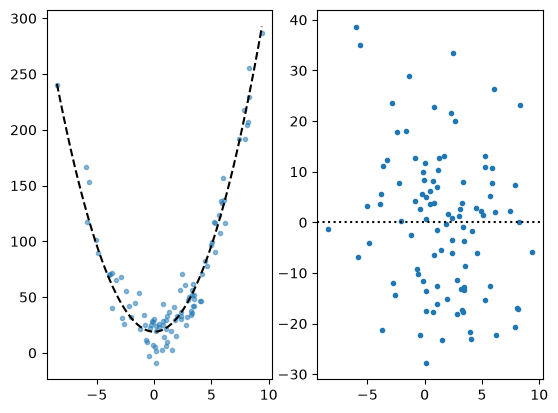

In [70]:
from scipy.optimize import curve_fit

def square_model(x, a, c):
    return a * x**2 + c

np.random.seed(42)
N = 100
x_obs = np.random.normal(2, 4, size=N)
noise = np.random.normal(0, 15, size=N)
y_obs = 3 * x_obs**2 + 20 + noise

popt, pcov = curve_fit(square_model, x_obs, y_obs)  # The model is fit automatically here.
print(popt)  # this is the parameter values that `curve_fit()` arrived at.

x = np.linspace(np.min(x_obs), np.max(x_obs), 60)
y = square_model(x, *popt)
y_pred = square_model(x_obs, *popt)
y_err = y_obs - y_pred

plt.figure()
plt.subplot(1, 2, 1)
plt.plot(x_obs, y_obs, '.', alpha=0.5)
plt.plot(x, y, '--k')
plt.subplot(1, 2, 2)
plt.plot(x_obs, y_err, '.')
plt.axhline(0, color='k', linestyle=':');